# Semana 11



## Fragament code in Section 14.2.5

In [2]:
class Graph:
	"""Representation of a simple graph using an adjacency map."""

	#------------------------- nested Vertex class -------------------------
	class Vertex:
		"""Lightweight vertex structure for a graph."""
		__slots__ = '_element'

		def __init__(self, x):
			"""Do not call constructor directly. Use Graph's insert_vertex(x)."""
			self._element = x

		def element(self):
			"""Return element associated with this vertex."""
			return self._element

		def __hash__(self):
			return hash(id(self))

	#------------------------- nested Edge class -------------------------
	class Edge:
		"""Lightweight edge structure for a graph."""
		__slots__ = '_origin', '_destination', '_element'

		def __init__(self, u, v, x):
			"""Do not call constructor directly. Use Graph's insert_edge(u,v,x)."""
			self._origin = u
			self._destination = v
			self._element = x

		def endpoints(self):
			"""Return (u,v) tuple for vertices u and v."""
			return self._origin, self._destination

		def opposite(self, v):
			"""Return the vertex that is opposite v on this edge."""
			return self._destination if v is self._origin else self._origin

		def element(self):
			"""Return element associated with this edge."""
			return self._element

		def __hash__(self):
			return hash((self._origin, self._destination))

	def __init__(self, directed=False):
		"""Create an empty graph (undirected, by default).

		Graph is directed if optional parameter is set to True.
		"""
		self._outgoing = {}
		# at most one edge {u,v}
		self._incoming = self._outgoing if not directed else {}

	def _is_directed(self):
		"""Return True if this is a directed graph, False if undirected.

		Property is based on the original declaration of the graph, not its contents.
		"""
		return self._incoming is not self._outgoing

	def vertex_count(self):
		"""Return the number of vertices in the graph."""
		return len(self._outgoing)

	def vertices(self):
		"""Return an iteration of all vertices of the graph."""
		return self._outgoing.keys()

	def edge_count(self):
		"""Return the number of edges in the graph."""
		total = sum(len(self._outgoing[v]) for v in self._outgoing)
		return total if self._is_directed() else total // 2

	def get_edge(self, u, v):
		"""Return the edge from u to v, or None if not adjacent."""
		return self._outgoing[u].get(v)

	def degree(self, v):
		"""Return number of edges incident to vertex v in the graph."""
		adj_out = len(self._outgoing[v])
		adj_in = len(self._incoming[v])
		return adj_out + adj_in if self._is_directed() else 2 * adj_out

	def incident_edges(self, v, outgoing=True):
		"""Return all edges incident to vertex v.

		If argument outgoing is True, return (u,v) edges where
		incident edge originated from u and arrived at v.
		If argument outgoing is False, return (v,u) edges where
		incident edge originated from v and arrived at u.
		"""
		vertex = self._outgoing if outgoing else self._incoming
		return list(vertex[v].values())

	def insert_vertex(self, x=None):
		"""Insert and return a new Vertex with element x."""
		v = self.Vertex(x)
		self._outgoing[v] = {}
		if self._is_directed():
			self._incoming[v] = {}
		return v

	def insert_edge(self, u, v, x=None):
		"""Insert and return a new Edge from u to v with auxiliary element x."""
		e = self.Edge(u, v, x)
		self._outgoing[u][v] = e
		self._incoming[v][u] = e
		return e

# -------- Ejemplo de uso --------
G = Graph(directed=False)
vA = G.insert_vertex('A')
vB = G.insert_vertex('B')
vC = G.insert_vertex('C')

G.insert_edge(vA, vB, 'A-B')
G.insert_edge(vB, vC, 'B-C')
G.insert_edge(vC, vA, 'C-A')

print('Vertices:', [v.element() for v in G.vertices()])
print('Vertex count:', G.vertex_count())
print('Edge count:', G.edge_count())
print('Degree(A):', G.degree(vA))
print('Incident edges at B:', [e.element() for e in G.incident_edges(vB)])


Vertices: ['A', 'B', 'C']
Vertex count: 3
Edge count: 3
Degree(A): 4
Incident edges at B: ['A-B', 'B-C']


**R-14.1** Draw a simple undirected graph $G$ that has 12 vertices, 18 edges, and 3 connected components.

**R-14.2** If $G$ is a simple undirected graph with 12 vertices and 3 connected components, what is the largest number of edges it might have?

45 aristas.

**R-14.3** Draw an adjacency matrix representation of the undirected graph shown in Figure 14.1.

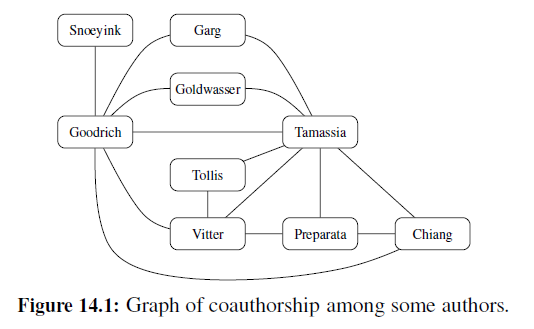

**R-14.4** Draw an adjacency list representation of the undirected graph shown in Figure 14.1.

Snoeyink: [Goodrich]

Garg: [Goodrich, Tamassia]

Goldwasser: [Goodrich, Tamassia]

Goodrich: [Snoeyink, Garg, Goldwasser, Tamassia, Vitter, Chiang]

Tamassia: [Garg, Goldwasser, Goodrich, Tollis, Vitter, Preparata, Chiang]

Tollis: [Tamassia, Vitter]

Vitter: [Goodrich, Tamassia, Tollis, Preparata]

Preparata: [Tamassia, Vitter, Chiang]

Chiang: [Goodrich, Tamassia, Preparata]

**R-14.5** Draw a simple, connected, directed graph with 8 vertices and 16 edges such that the in-degree and out-degree of each vertex is 2. Show that there is a single (nonsimple) cycle that includes all the edges of your graph, that is, you can trace all the edges in their respective directions without ever lifting your pencil. (Such a cycle is called an Euler tour.)

**R-14.7** Give pseudo-code for performing the operation insert_edge(u,v,x) in $O(1)$ time using the adjacency matrix representation.

insert_edge(u, v, x)

    Crear un objeto arista e, guardar u, v y su valor x.

    Asignar la arista e en la matriz de adyacencia en la posición de la fila u y columna v:

        matriz[u][v] = e

    Si el grafo no es dirigido, guardar la misma arista en la posición opuesta para indicar que son adyacentes en ambas direcciones:

        matriz[v][u] = e

    return arista e

**C-14.37** Give a Python implementation of the remove_vertex(v) method for our adjacency map implementation of Section 14.2.5, making sure your implementation works for both directed and undirected graphs. Your method should run in $O(deg(v))$ time.

In [3]:
class Graph:
    """Representation of a simple graph using an adjacency map."""

    #------------------------- nested Vertex class -------------------------
    class Vertex:
        """Lightweight vertex structure for a graph."""
        __slots__ = '_element'

        def __init__(self, x):
            """Do not call constructor directly. Use Graph's insert_vertex(x)."""
            self._element = x

        def element(self):
            """Return element associated with this vertex."""
            return self._element

        def __hash__(self):
            return hash(id(self))

    #------------------------- nested Edge class -------------------------
    class Edge:
        """Lightweight edge structure for a graph."""
        __slots__ = '_origin', '_destination', '_element'

        def __init__(self, u, v, x):
            """Do not call constructor directly. Use Graph's insert_edge(u,v,x)."""
            self._origin = u
            self._destination = v
            self._element = x

        def endpoints(self):
            """Return (u,v) tuple for vertices u and v."""
            return self._origin, self._destination

        def opposite(self, v):
            """Return the vertex that is opposite v on this edge."""
            return self._destination if v is self._origin else self._origin

        def element(self):
            """Return element associated with this edge."""
            return self._element

        def __hash__(self):
            return hash((self._origin, self._destination))

    def __init__(self, directed=False):
        """Create an empty graph (undirected, by default).

        Graph is directed if optional parameter is set to True.
        """
        self._outgoing = {}
        # at most one edge {u,v}
        self._incoming = self._outgoing if not directed else {}

    def _is_directed(self):
        """Return True if this is a directed graph, False if undirected.

        Property is based on the original declaration of the graph, not its contents.
        """
        return self._incoming is not self._outgoing

    def vertex_count(self):
        """Return the number of vertices in the graph."""
        return len(self._outgoing)

    def vertices(self):
        """Return an iteration of all vertices of the graph."""
        return self._outgoing.keys()

    def edge_count(self):
        """Return the number of edges in the graph."""
        total = sum(len(self._outgoing[v]) for v in self._outgoing)
        return total if self._is_directed() else total // 2

    def get_edge(self, u, v):
        """Return the edge from u to v, or None if not adjacent."""
        return self._outgoing[u].get(v)

    def degree(self, v):
        """Return number of edges incident to vertex v in the graph."""
        adj_out = len(self._outgoing[v])
        adj_in = len(self._incoming[v])
        return adj_out + adj_in if self._is_directed() else adj_out

    def incident_edges(self, v, outgoing=True):
        """Return all edges incident to vertex v.

        If argument outgoing is True, return (u,v) edges where
        incident edge originated from u and arrived at v.
        If argument outgoing is False, return (v,u) edges where
        incident edge originated from v and arrived at u.
        """
        vertex = self._outgoing if outgoing else self._incoming
        return list(vertex[v].values())

    def insert_vertex(self, x=None):
        """Insert and return a new Vertex with element x."""
        v = self.Vertex(x)
        self._outgoing[v] = {}
        if self._is_directed():
            self._incoming[v] = {}
        return v

    def insert_edge(self, u, v, x=None):
        """Insert and return a new Edge from u to v with auxiliary element x."""
        e = self.Edge(u, v, x)
        self._outgoing[u][v] = e
        self._incoming[v][u] = e
        return e

    def remove_vertex(self, v):
        for i in list(self._outgoing[v]):
            del self._incoming[i][v]
        if self._is_directed():
            for i in list(self._incoming[v]):
                del self._outgoing[i][v]
            del self._incoming[v]
        del self._outgoing[v]


In [4]:
G = Graph(directed=False)
vA = G.insert_vertex('A')
vB = G.insert_vertex('B')
vC = G.insert_vertex('C')

print('Vertices:', [v.element() for v in G.vertices()])
print("Eliminar vértice B")
G.remove_vertex(vA)
print("Lista actual de vértices: ", [v.element() for v in G.vertices()] )

Vertices: ['A', 'B', 'C']
Eliminar vértice B
Lista actual de vértices:  ['B', 'C']


**C-14.38** Give a Python implementation of the remove_edge(e) method for our adjacency map implementation of Section 14.2.5, making sure your implementation works for both directed and undirected graphs. Your method should run in $O(1)$ time.

In [5]:
class Graph:
    """Representation of a simple graph using an adjacency map."""

    #------------------------- nested Vertex class -------------------------
    class Vertex:
        """Lightweight vertex structure for a graph."""
        __slots__ = '_element'

        def __init__(self, x):
            """Do not call constructor directly. Use Graph's insert_vertex(x)."""
            self._element = x

        def element(self):
            """Return element associated with this vertex."""
            return self._element

        def __hash__(self):
            return hash(id(self))

    #------------------------- nested Edge class -------------------------
    class Edge:
        """Lightweight edge structure for a graph."""
        __slots__ = '_origin', '_destination', '_element'

        def __init__(self, u, v, x):
            """Do not call constructor directly. Use Graph's insert_edge(u,v,x)."""
            self._origin = u
            self._destination = v
            self._element = x

        def endpoints(self):
            """Return (u,v) tuple for vertices u and v."""
            return self._origin, self._destination

        def opposite(self, v):
            """Return the vertex that is opposite v on this edge."""
            return self._destination if v is self._origin else self._origin

        def element(self):
            """Return element associated with this edge."""
            return self._element

        def __hash__(self):
            return hash((self._origin, self._destination))

    def __init__(self, directed=False):
        """Create an empty graph (undirected, by default).

        Graph is directed if optional parameter is set to True.
        """
        self._outgoing = {}
        # at most one edge {u,v}
        self._incoming = self._outgoing if not directed else {}

    def _is_directed(self):
        """Return True if this is a directed graph, False if undirected.

        Property is based on the original declaration of the graph, not its contents.
        """
        return self._incoming is not self._outgoing

    def vertex_count(self):
        """Return the number of vertices in the graph."""
        return len(self._outgoing)

    def vertices(self):
        """Return an iteration of all vertices of the graph."""
        return self._outgoing.keys()

    def edge_count(self):
        """Return the number of edges in the graph."""
        total = sum(len(self._outgoing[v]) for v in self._outgoing)
        return total if self._is_directed() else total // 2

    def get_edge(self, u, v):
        """Return the edge from u to v, or None if not adjacent."""
        return self._outgoing[u].get(v)

    def degree(self, v):
        """Return number of edges incident to vertex v in the graph."""
        adj_out = len(self._outgoing[v])
        adj_in = len(self._incoming[v])
        return adj_out + adj_in if self._is_directed() else adj_out

    def incident_edges(self, v, outgoing=True):
        """Return all edges incident to vertex v.

        If argument outgoing is True, return (u,v) edges where
        incident edge originated from u and arrived at v.
        If argument outgoing is False, return (v,u) edges where
        incident edge originated from v and arrived at u.
        """
        vertex = self._outgoing if outgoing else self._incoming
        return list(vertex[v].values())

    def insert_vertex(self, x=None):
        """Insert and return a new Vertex with element x."""
        v = self.Vertex(x)
        self._outgoing[v] = {}
        if self._is_directed():
            self._incoming[v] = {}
        return v

    def insert_edge(self, u, v, x=None):
        """Insert and return a new Edge from u to v with auxiliary element x."""
        e = self.Edge(u, v, x)
        self._outgoing[u][v] = e
        self._incoming[v][u] = e
        return e

    def remove_vertex(self, v):
        for i in list(self._outgoing[v]):
            del self._incoming[i][v]
        if self._is_directed():
            for i in list(self._incoming[v]):
                del self._outgoing[i][v]
            del self._incoming[v]
        del self._outgoing[v]

    def remove_edge(self, e):
        u, v = e.endpoints()
        del self._outgoing[u][v]
        del self._incoming[v][u]

In [7]:
G = Graph(directed=False)
vA = G.insert_vertex('A')
vB = G.insert_vertex('B')
vC = G.insert_vertex('C')
eAB = G.insert_edge(vA, vB, 'A-B')
eBC = G.insert_edge(vB, vC, 'B-C')
eCA = G.insert_edge(vC, vA, 'C-A')

print('Vertices:', [v.element() for v in G.vertices()])
print("Aristas: ", [e.element() for e in G.incident_edges(vB)])
print("Eliminar Arista A-B")
G.remove_edge(eAB)
print("Aristas: ", [e.element() for e in G.incident_edges(vB)])

Vertices: ['A', 'B', 'C']
Aristas:  ['A-B', 'B-C']
Eliminar Arista A-B
Aristas:  ['B-C']


**C-14.43** Implement an algorithm that returns a cycle in a directed graph $\vec{G}$, if one exists.

In [9]:
class Graph:
    """Representation of a simple graph using an adjacency map."""

    #------------------------- nested Vertex class -------------------------
    class Vertex:
        """Lightweight vertex structure for a graph."""
        __slots__ = '_element'

        def __init__(self, x):
            """Do not call constructor directly. Use Graph's insert_vertex(x)."""
            self._element = x

        def element(self):
            """Return element associated with this vertex."""
            return self._element

        def __hash__(self):
            return hash(id(self))

    #------------------------- nested Edge class -------------------------
    class Edge:
        """Lightweight edge structure for a graph."""
        __slots__ = '_origin', '_destination', '_element'

        def __init__(self, u, v, x):
            """Do not call constructor directly. Use Graph's insert_edge(u,v,x)."""
            self._origin = u
            self._destination = v
            self._element = x

        def endpoints(self):
            """Return (u,v) tuple for vertices u and v."""
            return self._origin, self._destination

        def opposite(self, v):
            """Return the vertex that is opposite v on this edge."""
            return self._destination if v is self._origin else self._origin

        def element(self):
            """Return element associated with this edge."""
            return self._element

        def __hash__(self):
            return hash((self._origin, self._destination))

    def __init__(self, directed=False):
        """Create an empty graph (undirected, by default).

        Graph is directed if optional parameter is set to True.
        """
        self._outgoing = {}
        # at most one edge {u,v}
        self._incoming = self._outgoing if not directed else {}

    def _is_directed(self):
        """Return True if this is a directed graph, False if undirected.

        Property is based on the original declaration of the graph, not its contents.
        """
        return self._incoming is not self._outgoing

    def vertex_count(self):
        """Return the number of vertices in the graph."""
        return len(self._outgoing)

    def vertices(self):
        """Return an iteration of all vertices of the graph."""
        return self._outgoing.keys()

    def edge_count(self):
        """Return the number of edges in the graph."""
        total = sum(len(self._outgoing[v]) for v in self._outgoing)
        return total if self._is_directed() else total // 2

    def get_edge(self, u, v):
        """Return the edge from u to v, or None if not adjacent."""
        return self._outgoing[u].get(v)

    def degree(self, v):
        """Return number of edges incident to vertex v in the graph."""
        adj_out = len(self._outgoing[v])
        adj_in = len(self._incoming[v])
        return adj_out + adj_in if self._is_directed() else adj_out

    def incident_edges(self, v, outgoing=True):
        """Return all edges incident to vertex v.

        If argument outgoing is True, return (u,v) edges where
        incident edge originated from u and arrived at v.
        If argument outgoing is False, return (v,u) edges where
        incident edge originated from v and arrived at u.
        """
        vertex = self._outgoing if outgoing else self._incoming
        return list(vertex[v].values())

    def insert_vertex(self, x=None):
        """Insert and return a new Vertex with element x."""
        v = self.Vertex(x)
        self._outgoing[v] = {}
        if self._is_directed():
            self._incoming[v] = {}
        return v

    def insert_edge(self, u, v, x=None):
        """Insert and return a new Edge from u to v with auxiliary element x."""
        e = self.Edge(u, v, x)
        self._outgoing[u][v] = e
        self._incoming[v][u] = e
        return e

    def remove_vertex(self, v):
        for i in list(self._outgoing[v]):
            del self._incoming[i][v]
        if self._is_directed():
            for i in list(self._incoming[v]):
                del self._outgoing[i][v]
            del self._incoming[v]
        del self._outgoing[v]

    def remove_edge(self, e):
        u, v = e.endpoints()
        del self._outgoing[u][v]
        del self._incoming[v][u]

    def find_cycle(self):
        for inicio in self.vertices():
            camino = [inicio]
            actual = inicio
            while len(self.incident_edges(actual)) > 0:
                e = self.incident_edges(actual)[0]
                siguiente = e.opposite(actual)
                if siguiente in camino:
                    camino.append(siguiente)
                    return camino
                camino.append(siguiente)
                actual = siguiente
        return None

In [11]:
G = Graph(directed=True)
vA = G.insert_vertex('A')
vB = G.insert_vertex('B')
vC = G.insert_vertex('C')

eAB = G.insert_edge(vA, vB, 'A-B')
eBC = G.insert_edge(vB, vC, 'B-C')
eCA = G.insert_edge(vC, vA, 'C-A')

print('Vertices:', [v.element() for v in G.vertices()])
print("Aristas: ", [e.element() for e in G.incident_edges(vB)])
ciclo = G.find_cycle()
if ciclo:
    print("Ciclo encontrado:", [v.element() for v in ciclo])
else:
    print("No hay ciclo")

Vertices: ['A', 'B', 'C']
Aristas:  ['B-C']
Ciclo encontrado: ['A', 'B', 'C', 'A']


**C-14.52** A graph $G$ is bipartite if its vertices can be partitioned into two sets $X$ and $Y$ such that every edge in $G$ has one end vertex in $X$ and the other in $Y$. Design an algorithm for determining if an undirected graph $G$ is bipartite (without knowing the sets $X$ and $Y$ in advance).

In [15]:
class Graph:
    """Representation of a simple graph using an adjacency map."""

    #------------------------- nested Vertex class -------------------------
    class Vertex:
        """Lightweight vertex structure for a graph."""
        __slots__ = '_element'

        def __init__(self, x):
            """Do not call constructor directly. Use Graph's insert_vertex(x)."""
            self._element = x

        def element(self):
            """Return element associated with this vertex."""
            return self._element

        def __hash__(self):
            return hash(id(self))

    #------------------------- nested Edge class -------------------------
    class Edge:
        """Lightweight edge structure for a graph."""
        __slots__ = '_origin', '_destination', '_element'

        def __init__(self, u, v, x):
            """Do not call constructor directly. Use Graph's insert_edge(u,v,x)."""
            self._origin = u
            self._destination = v
            self._element = x

        def endpoints(self):
            """Return (u,v) tuple for vertices u and v."""
            return self._origin, self._destination

        def opposite(self, v):
            """Return the vertex that is opposite v on this edge."""
            return self._destination if v is self._origin else self._origin

        def element(self):
            """Return element associated with this edge."""
            return self._element

        def __hash__(self):
            return hash((self._origin, self._destination))

    def __init__(self, directed=False):
        """Create an empty graph (undirected, by default).

        Graph is directed if optional parameter is set to True.
        """
        self._outgoing = {}
        # at most one edge {u,v}
        self._incoming = self._outgoing if not directed else {}

    def _is_directed(self):
        """Return True if this is a directed graph, False if undirected.

        Property is based on the original declaration of the graph, not its contents.
        """
        return self._incoming is not self._outgoing

    def vertex_count(self):
        """Return the number of vertices in the graph."""
        return len(self._outgoing)

    def vertices(self):
        """Return an iteration of all vertices of the graph."""
        return self._outgoing.keys()

    def edge_count(self):
        """Return the number of edges in the graph."""
        total = sum(len(self._outgoing[v]) for v in self._outgoing)
        return total if self._is_directed() else total // 2

    def get_edge(self, u, v):
        """Return the edge from u to v, or None if not adjacent."""
        return self._outgoing[u].get(v)

    def degree(self, v):
        """Return number of edges incident to vertex v in the graph."""
        adj_out = len(self._outgoing[v])
        adj_in = len(self._incoming[v])
        return adj_out + adj_in if self._is_directed() else adj_out

    def incident_edges(self, v, outgoing=True):
        """Return all edges incident to vertex v.

        If argument outgoing is True, return (u,v) edges where
        incident edge originated from u and arrived at v.
        If argument outgoing is False, return (v,u) edges where
        incident edge originated from v and arrived at u.
        """
        vertex = self._outgoing if outgoing else self._incoming
        return list(vertex[v].values())

    def insert_vertex(self, x=None):
        """Insert and return a new Vertex with element x."""
        v = self.Vertex(x)
        self._outgoing[v] = {}
        if self._is_directed():
            self._incoming[v] = {}
        return v

    def insert_edge(self, u, v, x=None):
        """Insert and return a new Edge from u to v with auxiliary element x."""
        e = self.Edge(u, v, x)
        self._outgoing[u][v] = e
        self._incoming[v][u] = e
        return e

    def remove_vertex(self, v):
        for i in list(self._outgoing[v]):
            del self._incoming[i][v]
        if self._is_directed():
            for i in list(self._incoming[v]):
                del self._outgoing[i][v]
            del self._incoming[v]
        del self._outgoing[v]

    def remove_edge(self, e):
        u, v = e.endpoints()
        del self._outgoing[u][v]
        del self._incoming[v][u]

    def is_bipartite(self):
        izquierda = []
        derecha = []

        for inicio in self.vertices():
            if inicio not in izquierda and inicio not in derecha:
                izquierda.append(inicio)
                lista = [inicio]
                while len(lista) > 0:
                    actual = lista.pop(0)
                    for arista in self.incident_edges(actual):
                        vecino = arista.opposite(actual)
                        if actual in izquierda:
                            if vecino in izquierda:
                                return False
                            if vecino not in derecha:
                                derecha.append(vecino)
                                lista.append(vecino)
                        else:
                            if vecino in derecha:
                                return False
                            if vecino not in izquierda:
                                izquierda.append(vecino)
                                lista.append(vecino)
        return True

In [16]:
G = Graph(directed=False)
vA = G.insert_vertex('A')
vB = G.insert_vertex('B')
vC = G.insert_vertex('C')

G.insert_edge(vA, vB, 'A-B')
G.insert_edge(vB, vC, 'B-C')

print('Vertices:', [v.element() for v in G.vertices()])
print("Aristas: ", [e.element() for e in G.incident_edges(vB)])

if G.is_bipartite():
    print("El grafo es bipartito")
else:
    print("El grafo NO es bipartito")

Vertices: ['A', 'B', 'C']
Aristas:  ['A-B', 'B-C']
El grafo es bipartito
